# Spotify Audio Features Analysis: PCA Visualization and Genre Prediction

This notebook applies **Principal Component Analysis (PCA)** and **machine learning** to a curated Spotify dataset.

## Goals
- understand the dataset and selected genres
- standardize the audio features
- study the correlation matrix and PCA structure
- visualize songs in the first factorial plane
- compare genre classification on:
  - original audio features
  - PCA with 2 components
  - PCA retaining 95% of the variance

The project uses five genres: **Pop, Rock, Hip-Hop, Electronic, and Classical**.


In [21]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
%cd "/content/drive/MyDrive/spotify-pca-genre-prediction"
!pip -q install -r requirements.txt

/content/drive/MyDrive/spotify-pca-genre-prediction


In [23]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

candidate_roots = [Path.cwd(), Path.cwd().parent]
project_root = None
for candidate in candidate_roots:
    if (candidate / 'data' / 'spotify_tracks_selected.csv').exists():
        project_root = candidate
        break

if project_root is None:
    drive_root = Path('/content/drive/MyDrive')
    if drive_root.exists():
        matches = list(drive_root.glob('**/spotify-pca-genre-prediction'))
        if matches:
            project_root = matches[0]

if project_root is None:
    raise FileNotFoundError('Could not locate the spotify-pca-genre-prediction folder.')

sys.path.insert(0, str(project_root / 'src'))

from spotify_pca_ml import (
    DATA_PATH,
    FEATURE_COLUMNS,
    IMAGES_DIR,
    OUTPUTS_DIR,
    SELECTED_GENRES,
    compute_pca_artifacts,
    ensure_directories,
    export_model_outputs,
    export_pca_tables,
    load_dataset,
    run_model_experiments,
    save_correlation_circle,
    save_correlation_heatmap,
    save_explained_variance_plot,
    save_logistic_confusion_matrices,
    save_model_comparison_plot,
    save_pca_scatter_plot,
)

pd.set_option('display.max_columns', None)
project_root

PosixPath('/content/drive/MyDrive/spotify-pca-genre-prediction')

## 1. Load the dataset

The local dataset is a balanced subset built from the public `SpotifyFeatures.csv` file. Each selected genre contains **1500 tracks**, so the classification task is balanced.


In [24]:
dataframe = load_dataset(DATA_PATH)
print('Dataset shape:', dataframe.shape)
print('Selected genres:', ', '.join(SELECTED_GENRES))
print()
print('Class balance:')
print(dataframe['genre'].value_counts())
dataframe.head()

Dataset shape: (7500, 15)
Selected genres: Pop, Rock, Hip-Hop, Electronic, Classical

Class balance:
genre
Pop           1500
Rock          1500
Hip-Hop       1500
Electronic    1500
Classical     1500
Name: count, dtype: int64


,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence
0,Pop,The Mayries,In My Mind,22niADFXztIbQ4wAimKPOw,70,0.857,0.643,131848,0.234,0.000000,0.0979,-9.547,0.0294,110.264,0.267
1,Pop,Sam Hunt,Downtown's Dead,5eFfsbjSouG8qOpg9ZqDl6,65,0.109,0.624,213987,0.696,0.000000,0.1320,-6.006,0.0469,82.001,0.392
2,Pop,gianni & kyle,independent,74qRj05oa0UzPKGQWYj9ik,58,0.403,0.484,192000,0.545,0.000000,0.1150,-7.883,0.3700,82.388,0.398
3,Pop,Father John Misty,Chateau Lobby #4 (in C for Two Virgins),2eg2gvPXuwZ9FyrPaLgrXi,58,0.209,0.436,170840,0.804,0.000000,0.1710,-4.907,0.0409,188.061,0.784
4,Pop,Jon Bellion,Human,23n7KwXOXC9giXTz5Q71NH,57,0.689,0.685,205268,0.341,0.000003,0.1060,-8.528,0.1930,93.911,0.692


## 2. Selected variables

The numerical variables used for PCA and machine learning are the following Spotify audio features plus track popularity.


In [25]:
FEATURE_COLUMNS

['danceability',
 'energy',
 'loudness',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'popularity']

In [26]:
dataframe[FEATURE_COLUMNS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
danceability,7500.0,0.566,0.197,0.062,0.438,0.590,0.714,0.986
energy,7500.0,0.581,0.279,0.001,0.413,0.638,0.802,0.998
loudness,7500.0,-9.835,7.314,-46.052,-11.345,-7.199,-5.171,1.585
speechiness,7500.0,0.103,0.106,0.022,0.038,0.052,0.117,0.922
acousticness,7500.0,0.313,0.359,0.000,0.021,0.136,0.569,0.996
instrumentalness,7500.0,0.205,0.342,0.000,0.000,0.000,0.306,0.985
liveness,7500.0,0.189,0.156,0.015,0.095,0.123,0.233,0.991
valence,7500.0,0.418,0.249,0.024,0.212,0.393,0.606,0.982
tempo,7500.0,118.648,30.100,34.469,94.458,119.040,140.004,220.169
popularity,7500.0,50.254,17.263,0.000,37.000,54.000,63.000,99.000


## 3. PCA preparation

We center and standardize the features, compute the correlation matrix, then extract eigenvalues, explained variance, scores, and loadings.


In [27]:
ensure_directories()
artifacts = compute_pca_artifacts(dataframe)

pca_summary = pd.DataFrame(
    {
        'eigenvalue': artifacts.eigenvalues.round(4),
        'explained_variance_percent': artifacts.explained_variance_percent.round(2),
        'cumulative_variance_percent': artifacts.cumulative_variance_percent.round(2),
    },
    index=[f'PC{i + 1}' for i in range(len(FEATURE_COLUMNS))],
)

pca_summary

,eigenvalue,explained_variance_percent,cumulative_variance_percent
PC1,4.3202,43.20,43.20
PC2,1.1535,11.54,54.74
PC3,0.9822,9.82,64.56
PC4,0.9000,9.00,73.56
PC5,0.7681,7.68,81.24
PC6,0.6986,6.99,88.23
PC7,0.4717,4.72,92.94
PC8,0.4112,4.11,97.06
PC9,0.2006,2.01,99.06
PC10,0.0938,0.94,100.00


In [28]:
artifacts.correlation_matrix

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,popularity
danceability,1.0000,0.4693,0.5729,0.3112,-0.5479,-0.4178,-0.0034,0.4965,0.0976,0.4359
energy,0.4693,1.0000,0.8642,0.1971,-0.8322,-0.4559,0.1831,0.4421,0.2828,0.3973
loudness,0.5729,0.8642,1.0000,0.2235,-0.7931,-0.5887,0.1343,0.4080,0.2671,0.5201
speechiness,0.3112,0.1971,0.2235,1.0000,-0.2119,-0.2542,0.1375,0.1221,0.1308,0.1365
acousticness,-0.5479,-0.8322,-0.7931,-0.2119,1.0000,0.4795,-0.1206,-0.3545,-0.2592,-0.4427
instrumentalness,-0.4178,-0.4559,-0.5887,-0.2542,0.4795,1.0000,-0.0846,-0.3407,-0.1301,-0.5228
liveness,-0.0034,0.1831,0.1343,0.1375,-0.1206,-0.0846,1.0000,0.0526,0.0669,-0.0436
valence,0.4965,0.4421,0.4080,0.1221,-0.3545,-0.3407,0.0526,1.0000,0.1094,0.3402
tempo,0.0976,0.2828,0.2671,0.1308,-0.2592,-0.1301,0.0669,0.1094,1.0000,0.1031
popularity,0.4359,0.3973,0.5201,0.1365,-0.4427,-0.5228,-0.0436,0.3402,0.1031,1.0000


## 4. PCA visualizations

The next cells generate the heatmap, scree plot, 2D PCA scatter plot, and correlation circle.


In [29]:
save_correlation_heatmap(artifacts.correlation_matrix, IMAGES_DIR / 'correlation_heatmap.png')
save_explained_variance_plot(artifacts, IMAGES_DIR / 'explained_variance.png')
save_pca_scatter_plot(artifacts, IMAGES_DIR / 'pca_scatter.png')
save_correlation_circle(artifacts, IMAGES_DIR / 'correlation_circle.png')

for image_name in ['correlation_heatmap.png', 'explained_variance.png', 'pca_scatter.png', 'correlation_circle.png']:
    display(Image(filename=str(IMAGES_DIR / image_name)))

Output hidden; open in https://colab.research.google.com to view.

## 5. Variable interpretation

The table below shows the contribution of each audio feature to the first two principal components.


In [30]:
artifacts.contributions[['PC1', 'PC2']].sort_values('PC1', ascending=False).round(2)

,PC1,PC2
loudness,19.01,0.27
energy,17.15,2.67
acousticness,16.91,0.83
danceability,12.08,4.98
instrumentalness,11.31,1.61
popularity,9.68,12.24
valence,8.04,4.46
speechiness,2.92,6.58
tempo,2.34,18.55
liveness,0.55,47.82


In [31]:
artifacts.variable_quality[['PC1', 'PC2']].round(3)

,PC1,PC2
danceability,0.522,0.057
energy,0.741,0.031
loudness,0.821,0.003
speechiness,0.126,0.076
acousticness,0.730,0.010
instrumentalness,0.489,0.019
liveness,0.024,0.552
valence,0.347,0.051
tempo,0.101,0.214
popularity,0.418,0.141


In [32]:
artifacts.centroids.round(3)

,PC1,PC2
genre,,
Pop,-1.099,-0.453
Rock,-0.763,-0.245
Hip-Hop,-1.308,-0.072
Electronic,-0.348,0.642
Classical,3.519,0.128


## 6. Machine learning comparison

We compare three classifiers:
- Logistic Regression
- KNN
- Random Forest

Each model is trained on:
- the original standardized features
- only 2 PCA components
- PCA components retaining 95% of the variance


In [33]:
results_frame, reports, fitted_pipelines, split_data = run_model_experiments(dataframe)
results_frame

,experiment,accuracy,macro_f1,n_components_used
0,Random Forest - Original Features,0.7473,0.7477,original
1,Logistic Regression - Original Features,0.7327,0.7327,original
2,Logistic Regression - PCA (95% variance),0.7287,0.7284,8
3,KNN - Original Features,0.7213,0.7213,original
4,KNN - PCA (95% variance),0.7193,0.7184,8
5,Random Forest - PCA (95% variance),0.7107,0.7098,8
6,Logistic Regression - PCA (2 components),0.4980,0.4948,2
7,Random Forest - PCA (2 components),0.4740,0.4746,2
8,KNN - PCA (2 components),0.4667,0.4628,2


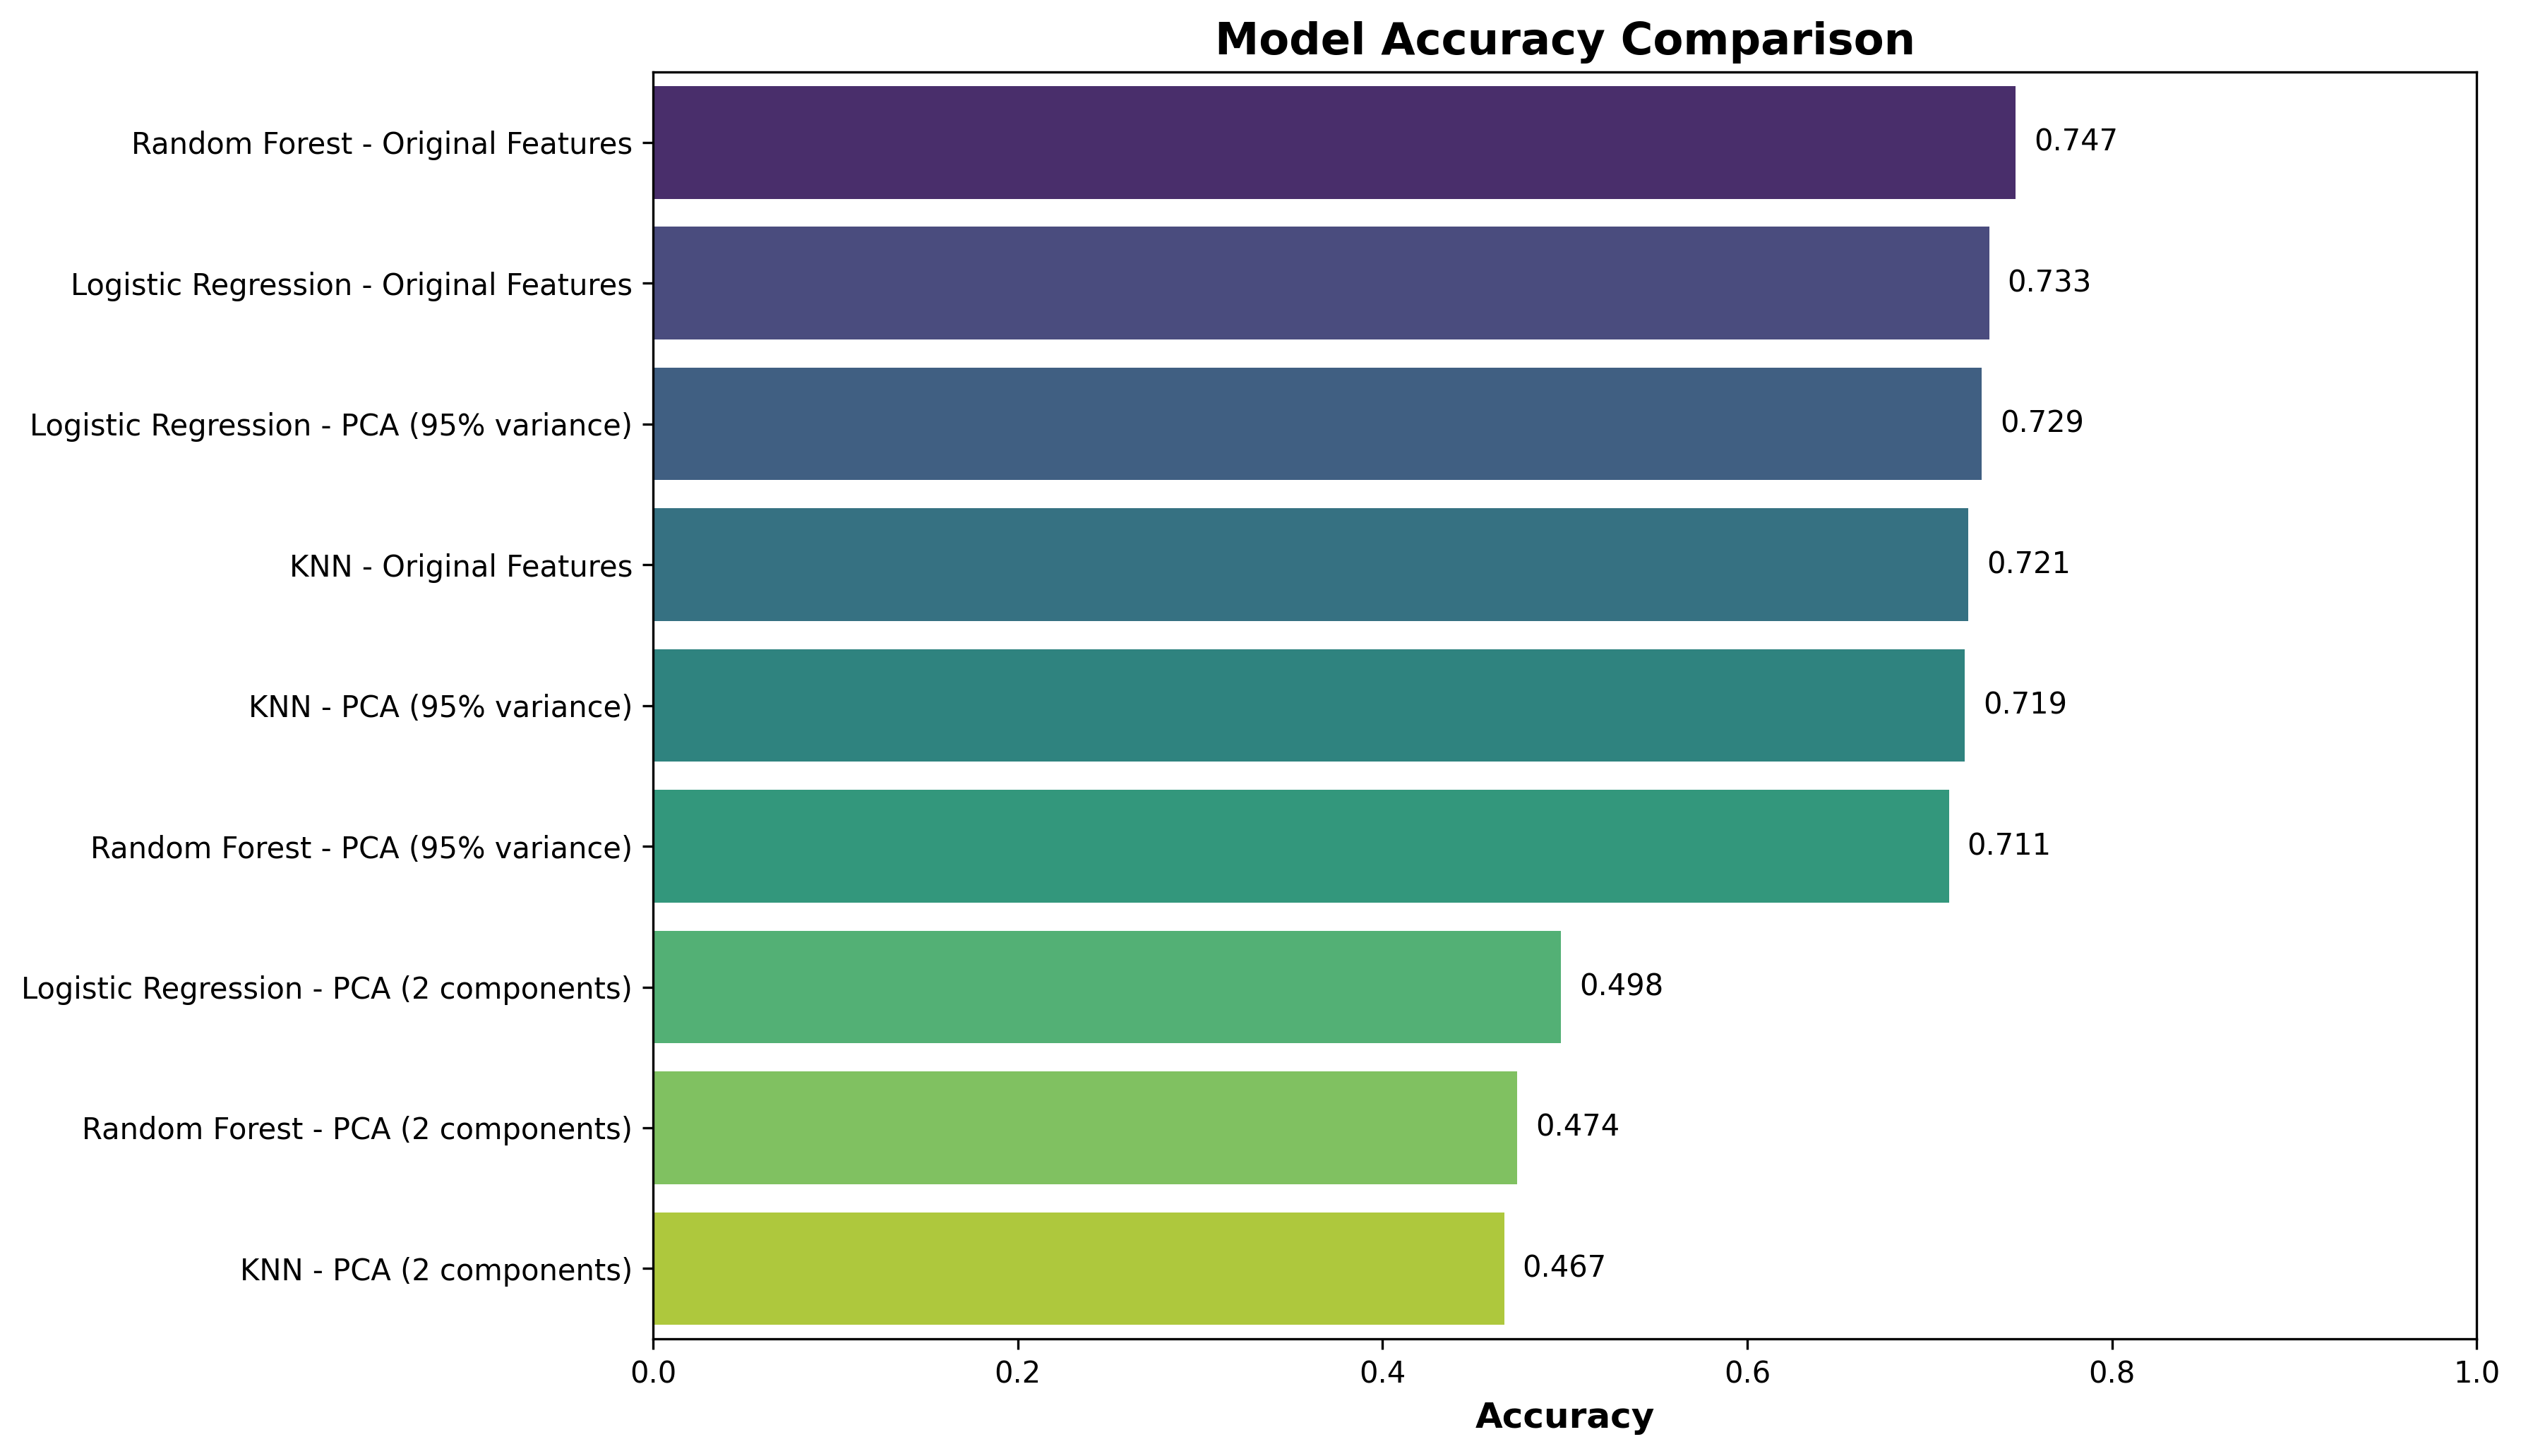

In [34]:
save_model_comparison_plot(results_frame, IMAGES_DIR / 'model_accuracy_comparison.png')
display(Image(filename=str(IMAGES_DIR / 'model_accuracy_comparison.png')))

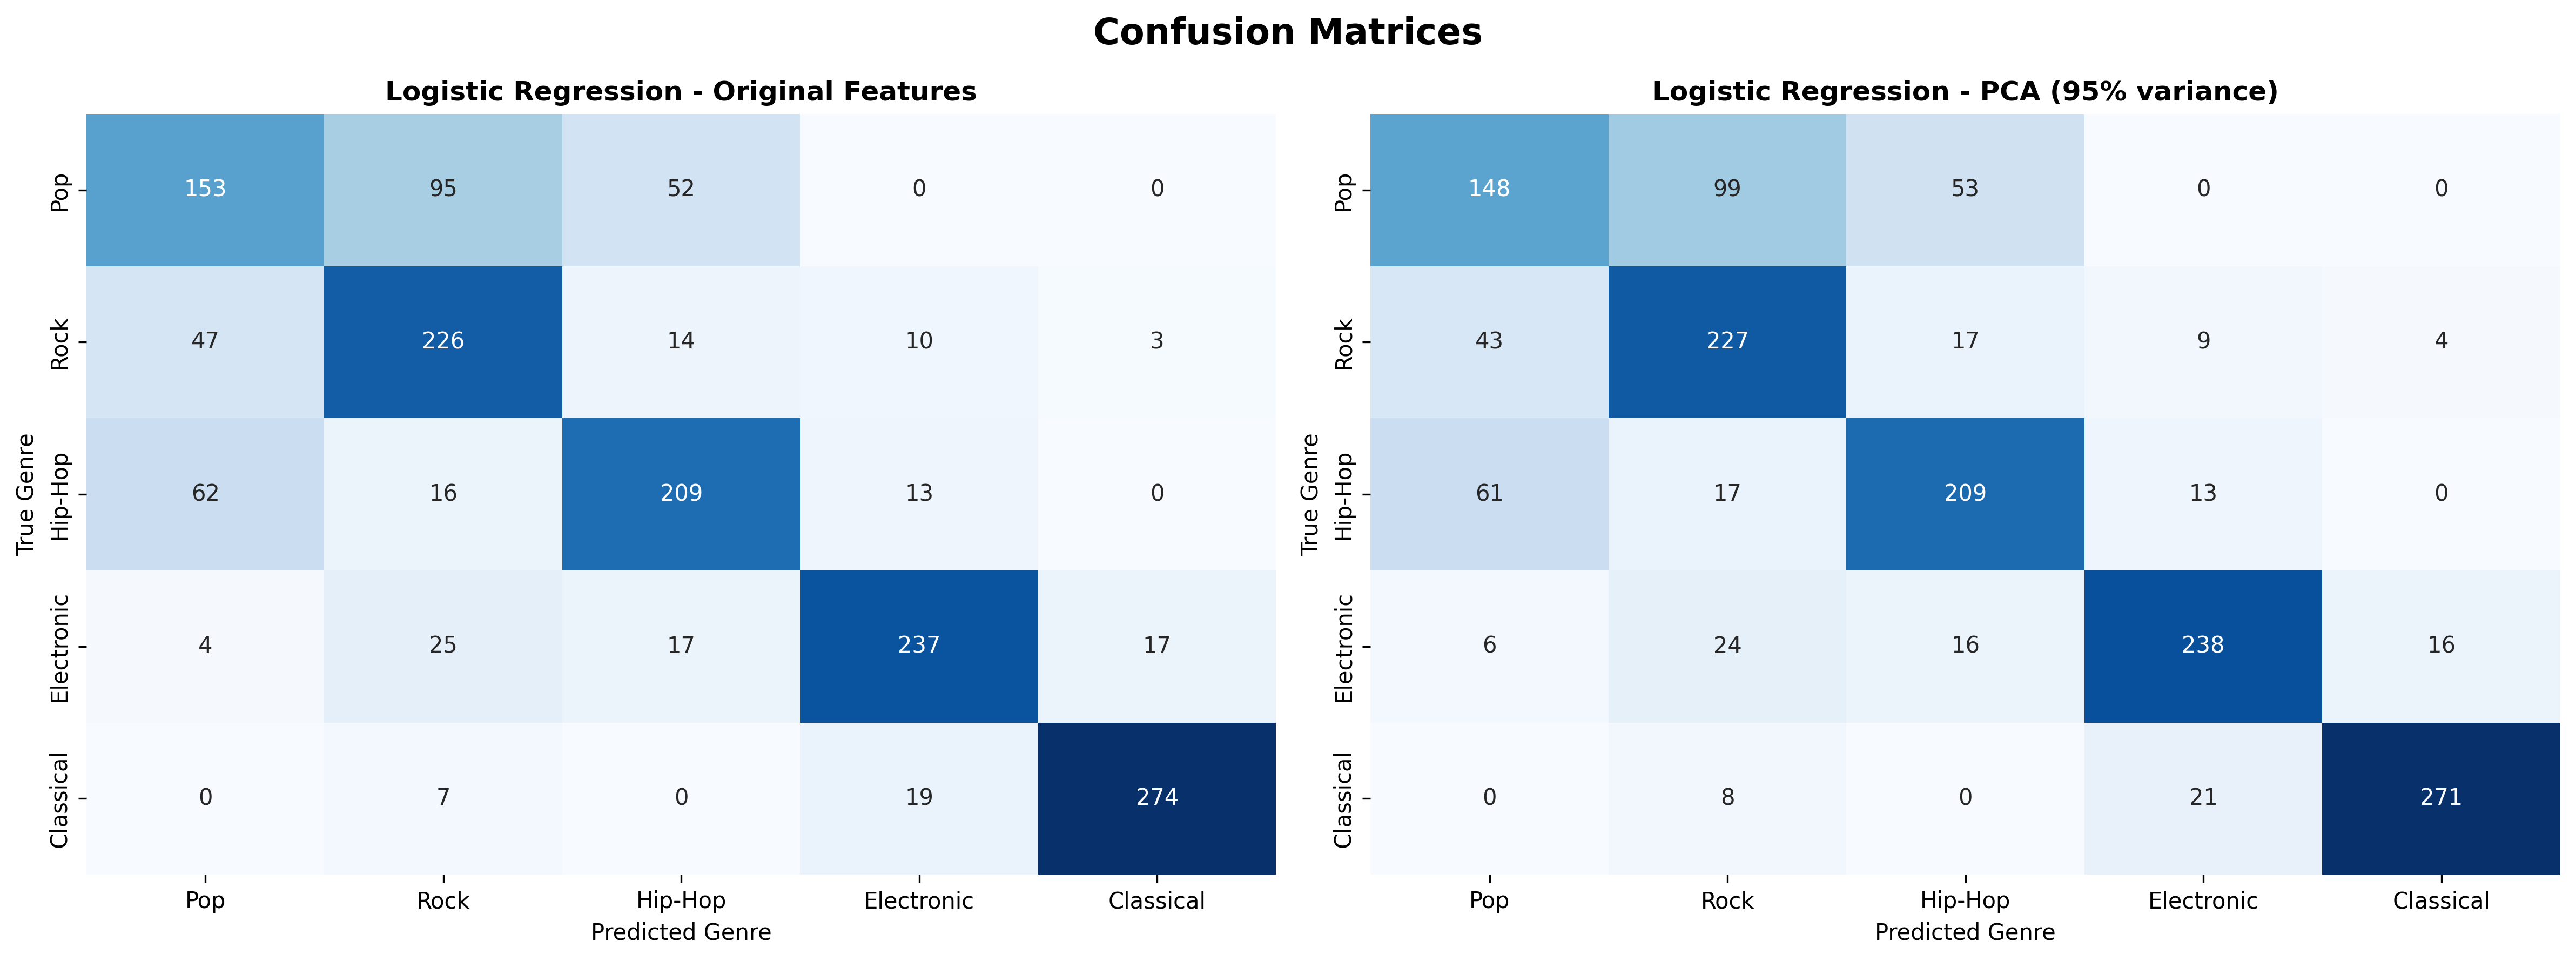

In [35]:
_, X_test, _, y_test = split_data
save_logistic_confusion_matrices(fitted_pipelines, X_test, y_test, IMAGES_DIR / 'confusion_matrices_logistic.png')
display(Image(filename=str(IMAGES_DIR / 'confusion_matrices_logistic.png')))

## 7. Detailed reports for the most important comparison

These two reports compare Logistic Regression on the original features versus Logistic Regression on PCA components retaining 95% of the variance.


In [36]:
print('Logistic Regression - Original Features')
print(reports['Logistic Regression - Original Features'])
print('-' * 80)
print('Logistic Regression - PCA (95% variance)')
print(reports['Logistic Regression - PCA (95% variance)'])

Logistic Regression - Original Features
              precision    recall  f1-score   support

   Classical     0.9320    0.9133    0.9226       300
  Electronic     0.8495    0.7900    0.8187       300
     Hip-Hop     0.7158    0.6967    0.7061       300
         Pop     0.5752    0.5100    0.5406       300
        Rock     0.6125    0.7533    0.6756       300

    accuracy                         0.7327      1500
   macro avg     0.7370    0.7327    0.7327      1500
weighted avg     0.7370    0.7327    0.7327      1500

--------------------------------------------------------------------------------
Logistic Regression - PCA (95% variance)
              precision    recall  f1-score   support

   Classical     0.9313    0.9033    0.9171       300
  Electronic     0.8470    0.7933    0.8193       300
     Hip-Hop     0.7085    0.6967    0.7025       300
         Pop     0.5736    0.4933    0.5305       300
        Rock     0.6053    0.7567    0.6726       300

    accuracy           

## 8. Save the project outputs

This exports the PCA tables and machine learning tables used by the README and report.


In [37]:
export_pca_tables(artifacts)
export_model_outputs(results_frame, reports)
print('Outputs saved to:', OUTPUTS_DIR)

Outputs saved to: /content/drive/MyDrive/spotify-pca-genre-prediction/outputs


## 9. Conclusion

### Main observations
- `PC1` explains the largest share of the variance and is strongly linked to **loudness**, **energy**, and **acousticness**.
- `PC2` is driven mainly by **liveness**, **tempo**, and **popularity**.
- The first two components are useful for **visualization**, but they only preserve about **54.74%** of the total variance.
- For classification, the **original features** perform best.
- PCA with **95% variance retained** keeps the accuracy very close to the original features, especially for **Logistic Regression** and **KNN**.
- PCA with only **2 components** is much worse for genre prediction.

### Final interpretation
PCA is excellent here for understanding and visualizing the structure of the Spotify audio features. For machine learning, a moderate-dimensional PCA representation can preserve most of the useful information, but an aggressive reduction to only two components loses too much information for accurate genre classification.
